
1. SUMMARY AVERAGES TABLE (Session: RTH)


,year,Trading_Days,Avg_Daily_Range_Pts,Median_Daily_Range_Pts,Min_Daily_Range_Pts,Max_Daily_Range_Pts
0,2019,258,83.29 pts,71.25 pts,8.50 pts,284.00 pts
1,2020,259,202.53 pts,177.75 pts,13.50 pts,701.00 pts
2,2021,258,193.10 pts,174.38 pts,15.25 pts,569.00 pts
3,2022,258,304.27 pts,285.25 pts,26.25 pts,925.25 pts
4,2023,257,197.48 pts,184.25 pts,22.50 pts,485.00 pts
5,2024,259,244.07 pts,223.00 pts,29.00 pts,921.75 pts
6,2025,257,320.50 pts,265.00 pts,32.00 pts,"2,184.50 pts"
7,2026,106,359.94 pts,351.88 pts,83.75 pts,745.00 pts
8,ALL-TIME (Total),1912,228.43 pts,201.62 pts,8.50 pts,"2,184.50 pts"



2. FULL DAILY RANGE TABLE (Total Days: 1,912)


,date,open,high,low,close,daily_range_pts
0,2019-01-02,6210.25,6409.25,6205.50,6373.25,203.75
1,2019-01-03,6277.75,6304.25,6148.50,6158.75,155.75
2,2019-01-04,6260.00,6462.00,6241.50,6435.50,220.50
3,2019-01-07,6441.25,6535.75,6422.25,6500.50,113.50
4,2019-01-08,6564.50,6586.25,6467.25,6564.50,119.00
...,...,...,...,...,...,...
1907,2026-05-26,29902.00,30118.75,29826.75,30079.75,292.00
1908,2026-05-27,30187.50,30192.00,29877.50,30047.25,314.50
1909,2026-05-28,30053.00,30344.50,29920.25,30306.25,424.25
1910,2026-05-29,30383.00,30536.00,30270.00,30397.50,266.00


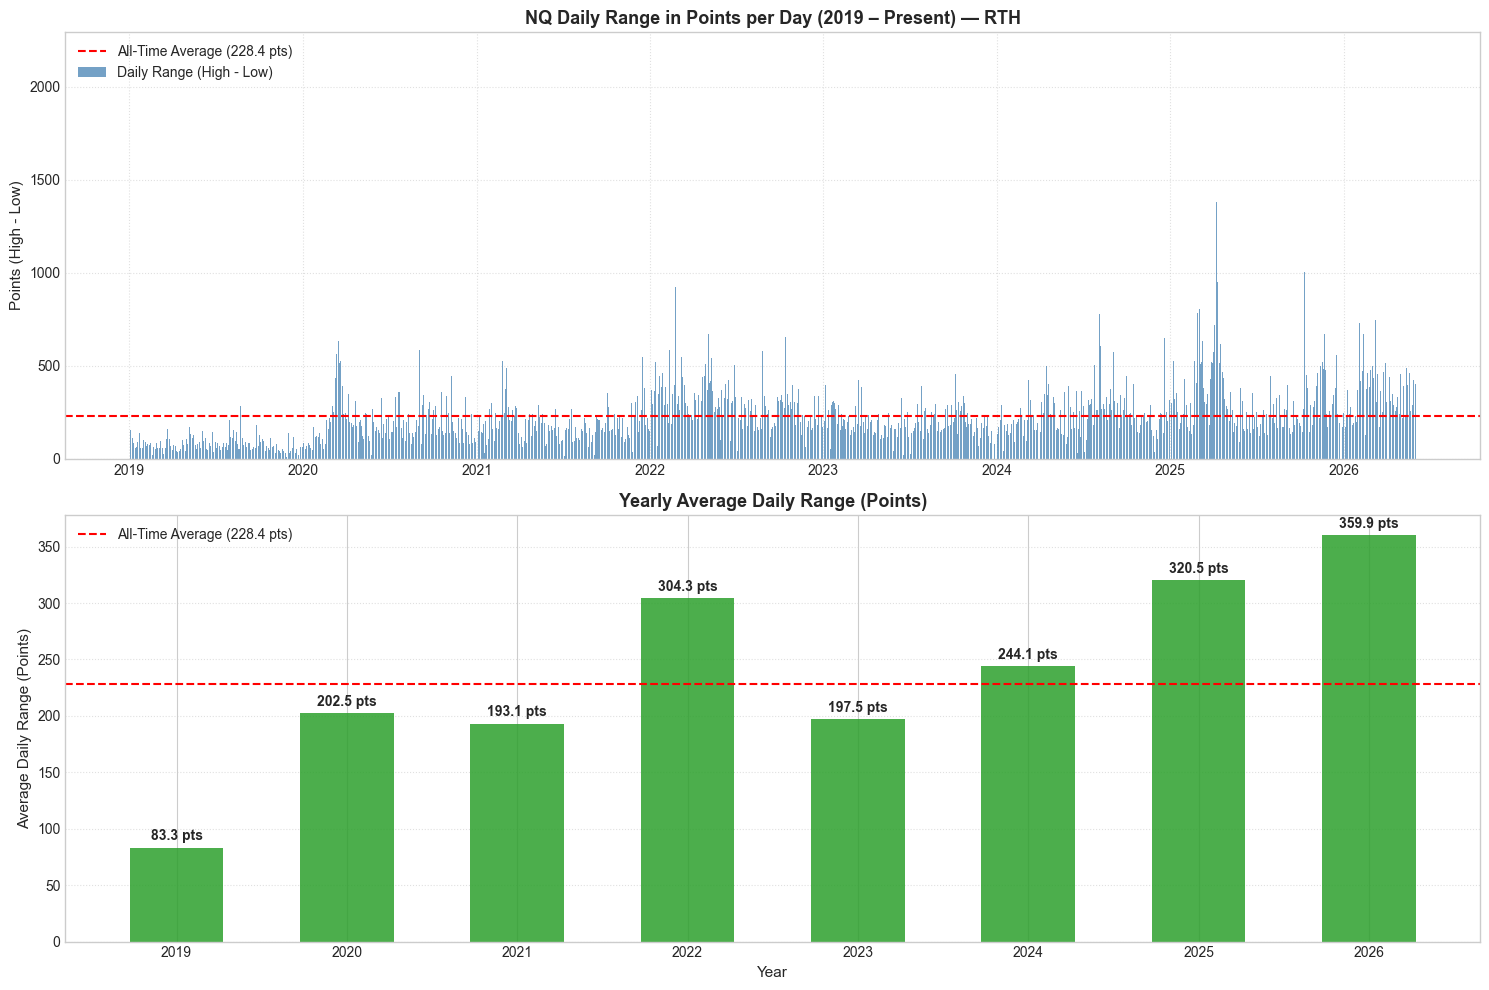

In [4]:
"""
NQ PURE DAILY RANGE ANALYZER (ATR = 1)
======================================
Computes the exact single-day point range (High - Low) for every individual day.
No rolling indicator windows.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ============================================================
# 1. CONFIGURATION
# ============================================================

PARQUET_PATH = "./data/nq_1min.parquet"
START_DATE = "2019-01-01"
END_DATE = None  # None = latest available date
TIMEZONE = "America/New_York"

# Session type: 'FULL_DAY' (00:00-23:59) or 'RTH' (09:30-16:00)
SESSION_TYPE = "RTH"

# ============================================================
# 2. LOAD DATA & CONVERT TIMEZONE
# ============================================================

if not os.path.exists(PARQUET_PATH):
    if os.path.exists("./nq_1min.parquet"):
        PARQUET_PATH = "./nq_1min.parquet"
    else:
        raise FileNotFoundError(f"Parquet file not found at: {PARQUET_PATH}")

df_1m = pd.read_parquet(PARQUET_PATH)

# Localize UTC and convert to America/New_York
if df_1m.index.tz is None:
    df_1m.index = pd.to_datetime(df_1m.index).tz_localize("UTC").tz_convert(TIMEZONE)
else:
    df_1m.index = pd.to_datetime(df_1m.index).tz_convert(TIMEZONE)

# Filter Start & End dates
if START_DATE:
    df_1m = df_1m[df_1m.index >= pd.Timestamp(START_DATE, tz=TIMEZONE)]
if END_DATE:
    df_1m = df_1m[df_1m.index < pd.Timestamp(END_DATE, tz=TIMEZONE) + pd.Timedelta(days=1)]

# ============================================================
# 3. COMPUTE DAILY HIGH, LOW, AND RANGE (POINTS)
# ============================================================

if SESSION_TYPE == "RTH":
    times = df_1m.index.time
    mask = (times >= pd.to_datetime("09:30").time()) & (times < pd.to_datetime("16:00").time())
    df_session = df_1m[mask]
else:
    df_session = df_1m

# Pure 1-day aggregation (ATR = 1)
daily_df = df_session.groupby(df_session.index.date).agg(
    open=('open', 'first'),
    high=('high', 'max'),
    low=('low', 'min'),
    close=('close', 'last'),
    volume=('volume', 'sum')
).reset_index()

daily_df.rename(columns={'index': 'date'}, inplace=True)
daily_df['date'] = pd.to_datetime(daily_df['date'])

# Pure daily range: High - Low
daily_df['daily_range_pts'] = daily_df['high'] - daily_df['low']
daily_df['year'] = daily_df['date'].dt.year

# Filter out empty zero-volume days (holidays/weekends)
daily_df = daily_df[daily_df['volume'] > 0].copy()

# ============================================================
# 4. SUMMARY AVERAGES TABLE (YEARLY & ALL-TIME)
# ============================================================

yearly_summary = daily_df.groupby('year').agg(
    Trading_Days=('daily_range_pts', 'count'),
    Avg_Daily_Range_Pts=('daily_range_pts', 'mean'),
    Median_Daily_Range_Pts=('daily_range_pts', 'median'),
    Min_Daily_Range_Pts=('daily_range_pts', 'min'),
    Max_Daily_Range_Pts=('daily_range_pts', 'max')
).reset_index()

overall_row = pd.DataFrame([{
    'year': 'ALL-TIME (Total)',
    'Trading_Days': len(daily_df),
    'Avg_Daily_Range_Pts': daily_df['daily_range_pts'].mean(),
    'Median_Daily_Range_Pts': daily_df['daily_range_pts'].median(),
    'Min_Daily_Range_Pts': daily_df['daily_range_pts'].min(),
    'Max_Daily_Range_Pts': daily_df['daily_range_pts'].max()
}])

summary_table = pd.concat([yearly_summary, overall_row], ignore_index=True)

# Formatted display
summary_display = summary_table.copy()
summary_display['Avg_Daily_Range_Pts'] = summary_display['Avg_Daily_Range_Pts'].map('{:,.2f} pts'.format)
summary_display['Median_Daily_Range_Pts'] = summary_display['Median_Daily_Range_Pts'].map('{:,.2f} pts'.format)
summary_display['Min_Daily_Range_Pts'] = summary_display['Min_Daily_Range_Pts'].map('{:,.2f} pts'.format)
summary_display['Max_Daily_Range_Pts'] = summary_display['Max_Daily_Range_Pts'].map('{:,.2f} pts'.format)

print("\n" + "=" * 90)
print(f"1. SUMMARY AVERAGES TABLE (Session: {SESSION_TYPE})")
print("=" * 90)
display(summary_display)

print("\n" + "=" * 90)
print(f"2. FULL DAILY RANGE TABLE (Total Days: {len(daily_df):,})")
print("=" * 90)
display(daily_df[['date', 'open', 'high', 'low', 'close', 'daily_range_pts']])

# ============================================================
# 5. GRAPHIC VISUALIZATION
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

# Plot 1: Every single day's range chronologically
all_time_mean = daily_df['daily_range_pts'].mean()
ax1.bar(daily_df['date'], daily_df['daily_range_pts'], color='#4682b4', width=1.0, alpha=0.75, label='Daily Range (High - Low)')
ax1.axhline(all_time_mean, color='red', linestyle='--', linewidth=1.5, label=f'All-Time Average ({all_time_mean:.1f} pts)')
ax1.set_title(f'NQ Daily Range in Points per Day (2019 – Present) — {SESSION_TYPE}', fontsize=13, fontweight='bold')
ax1.set_ylabel('Points (High - Low)', fontsize=11)
ax1.legend(loc='upper left')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot 2: Yearly Average Daily Range
yearly_plot = yearly_summary.copy()
bars = ax2.bar(yearly_plot['year'].astype(str), yearly_plot['Avg_Daily_Range_Pts'], color='#2ca02c', alpha=0.85, width=0.55)
ax2.axhline(all_time_mean, color='red', linestyle='--', linewidth=1.5, label=f'All-Time Average ({all_time_mean:.1f} pts)')
ax2.set_title('Yearly Average Daily Range (Points)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Average Daily Range (Points)', fontsize=11)
ax2.legend(loc='upper left')
ax2.grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    h = bar.get_height()
    ax2.annotate(f'{h:.1f} pts', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig("nq_daily_range_atr1.png", dpi=300)
plt.show()

Loading 1-minute NQ dataset...

1. SUMMARY AVERAGES TABLE — Custom Range (09:30:00 -> 12:00:00 Eastern)


,year,Trading_Days,Avg_Custom_Range,Median_Custom_Range,Min_Custom_Range,Max_Custom_Range
0,2019,258,65.64 pts,56.25 pts,8.50 pts,234.25 pts
1,2020,259,146.75 pts,127.25 pts,12.50 pts,701.00 pts
2,2021,258,148.38 pts,138.88 pts,12.00 pts,511.25 pts
3,2022,258,219.25 pts,210.12 pts,26.00 pts,630.00 pts
4,2023,257,147.18 pts,135.75 pts,21.50 pts,396.25 pts
5,2024,259,181.93 pts,166.50 pts,29.00 pts,680.00 pts
6,2025,257,238.12 pts,214.25 pts,32.00 pts,"1,688.00 pts"
7,2026,106,289.16 pts,266.75 pts,83.75 pts,639.00 pts
8,ALL-TIME (Total),1912,170.81 pts,151.50 pts,8.50 pts,"1,688.00 pts"



2. FULL DAILY CUSTOM RANGE TABLE (Total Days: 1,912)


,date,open,high,low,close,custom_range
0,2019-01-02,6210.25,6368.00,6205.50,6322.50,162.50
1,2019-01-03,6277.75,6304.25,6169.75,6254.00,134.50
2,2019-01-04,6260.00,6416.75,6241.50,6404.75,175.25
3,2019-01-07,6441.25,6520.50,6422.25,6519.00,98.25
4,2019-01-08,6564.50,6586.25,6467.25,6520.00,119.00
...,...,...,...,...,...,...
1907,2026-05-26,29902.00,30118.75,29826.75,29927.25,292.00
1908,2026-05-27,30187.50,30192.00,29877.50,29936.00,314.50
1909,2026-05-28,30053.00,30293.00,29920.25,30264.50,372.75
1910,2026-05-29,30383.00,30536.00,30270.00,30362.50,266.00


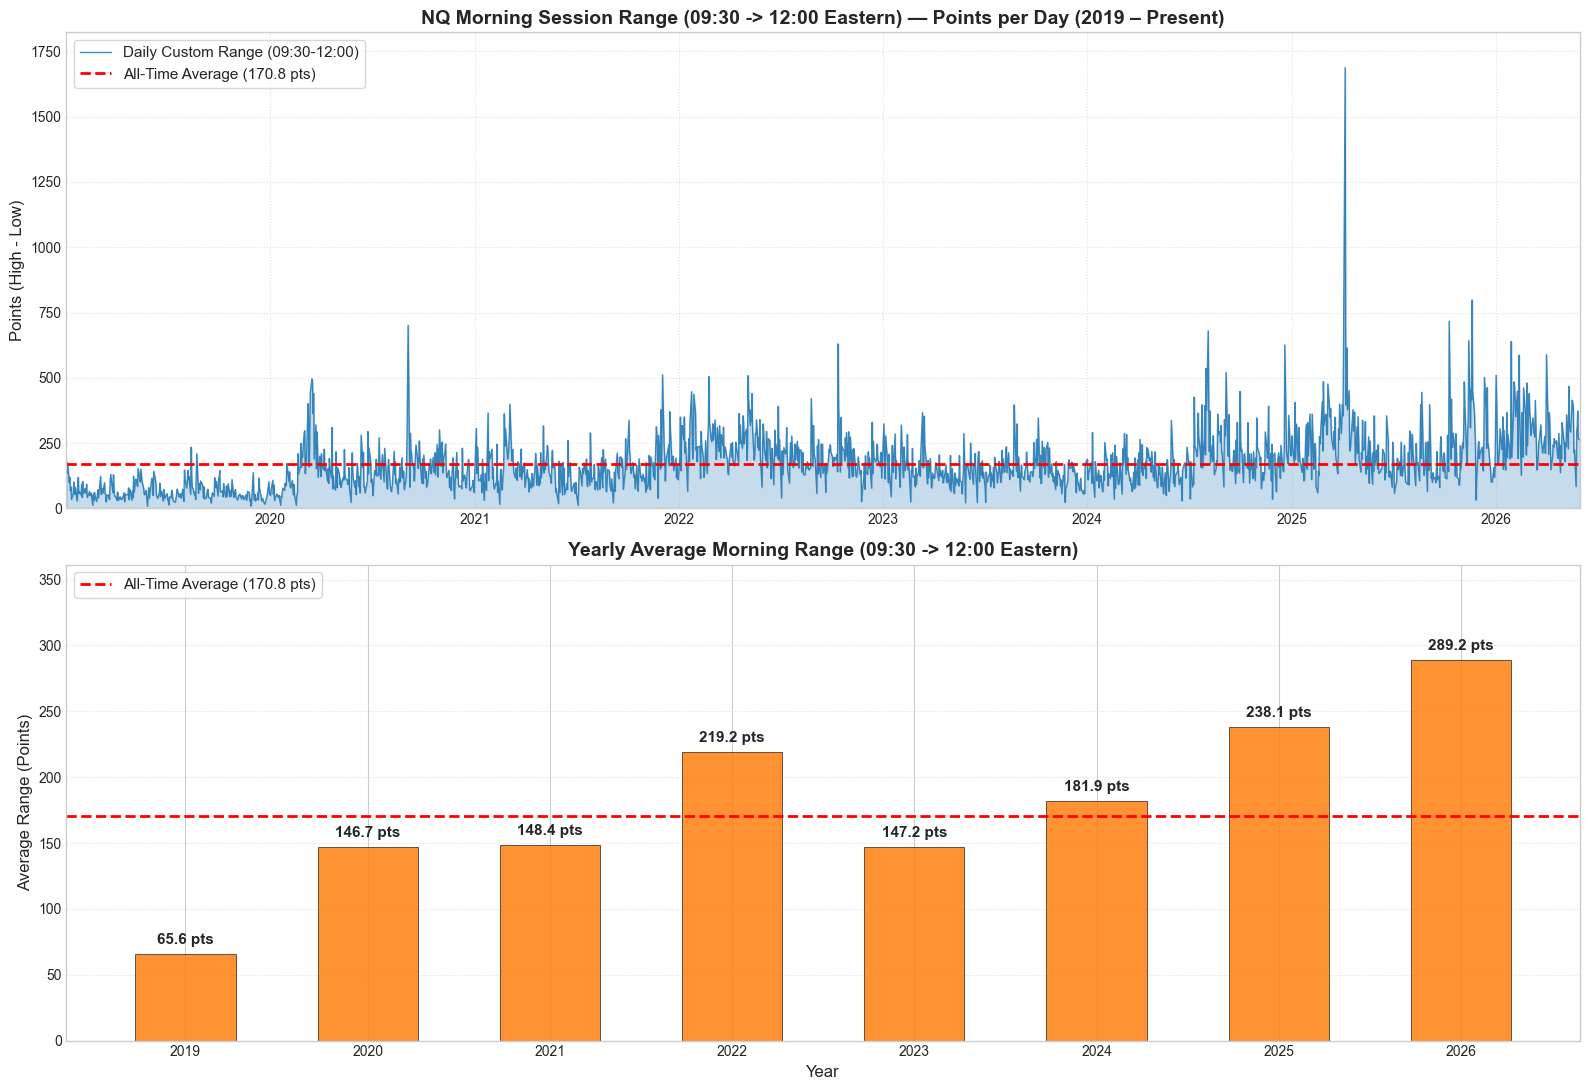


Visualization generated successfully and saved to: nq_custom_range_0930_1200.png


In [6]:
"""
NQ CUSTOM MORNING RANGE ANALYZER (09:30 -> 12:00 Eastern) — DEFINITIVE FIX
===========================================================================
Isolates the 09:30:00 to 12:00:00 America/New_York window for every trading day.
Calculates custom_range (High - Low in points) for that exact window.
Outputs summary table, full daily table, and robust graphic visualization.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ============================================================
# 1. CONFIGURATION
# ============================================================

PARQUET_PATH = "./data/nq_1min.parquet"
START_DATE = "2019-01-01"
END_DATE = None  # None = latest available date
TIMEZONE = "America/New_York"

WINDOW_START_TIME = pd.to_datetime("09:30:00").time()
WINDOW_END_TIME = pd.to_datetime("12:00:00").time()

# ============================================================
# 2. LOAD DATA & CONVERT TO EASTERN TIME
# ============================================================

if not os.path.exists(PARQUET_PATH):
    if os.path.exists("./nq_1min.parquet"):
        PARQUET_PATH = "./nq_1min.parquet"
    else:
        raise FileNotFoundError(f"Parquet file not found at: {PARQUET_PATH}")

print("Loading 1-minute NQ dataset...")
df_1m = pd.read_parquet(PARQUET_PATH)

# Localize UTC and convert to America/New_York
if df_1m.index.tz is None:
    df_1m.index = pd.to_datetime(df_1m.index).tz_localize("UTC").tz_convert(TIMEZONE)
else:
    df_1m.index = pd.to_datetime(df_1m.index).tz_convert(TIMEZONE)

# Date filter
if START_DATE:
    df_1m = df_1m[df_1m.index >= pd.Timestamp(START_DATE, tz=TIMEZONE)]
if END_DATE:
    df_1m = df_1m[df_1m.index < pd.Timestamp(END_DATE, tz=TIMEZONE) + pd.Timedelta(days=1)]

# ============================================================
# 3. FILTER CUSTOM WINDOW (09:30 -> 12:00) & AGGREGATE
# ============================================================

times = df_1m.index.time
mask_window = (times >= WINDOW_START_TIME) & (times < WINDOW_END_TIME)
df_custom = df_1m[mask_window].copy()

# Group by trading date
daily_custom = df_custom.groupby(df_custom.index.date).agg(
    open=('open', 'first'),
    high=('high', 'max'),
    low=('low', 'min'),
    close=('close', 'last'),
    volume=('volume', 'sum'),
    bars_count=('open', 'count')
).reset_index()

daily_custom.rename(columns={'index': 'date'}, inplace=True)
daily_custom['date'] = pd.to_datetime(daily_custom['date'])

# Exclude days with 0 volume / empty sessions
daily_custom = daily_custom[daily_custom['volume'] > 0].copy()

# Compute custom_range: High - Low in points
daily_custom['custom_range'] = daily_custom['high'] - daily_custom['low']
daily_custom['year'] = daily_custom['date'].dt.year

# ============================================================
# 4. SUMMARY AVERAGES TABLE (YEARLY & ALL-TIME)
# ============================================================

yearly_summary = daily_custom.groupby('year').agg(
    Trading_Days=('custom_range', 'count'),
    Avg_Custom_Range=('custom_range', 'mean'),
    Median_Custom_Range=('custom_range', 'median'),
    Min_Custom_Range=('custom_range', 'min'),
    Max_Custom_Range=('custom_range', 'max')
).reset_index()

overall_row = pd.DataFrame([{
    'year': 'ALL-TIME (Total)',
    'Trading_Days': len(daily_custom),
    'Avg_Custom_Range': daily_custom['custom_range'].mean(),
    'Median_Custom_Range': daily_custom['custom_range'].median(),
    'Min_Custom_Range': daily_custom['custom_range'].min(),
    'Max_Custom_Range': daily_custom['custom_range'].max()
}])

summary_table = pd.concat([yearly_summary, overall_row], ignore_index=True)

# Formatted display copy
summary_display = summary_table.copy()
summary_display['Avg_Custom_Range'] = summary_display['Avg_Custom_Range'].map('{:,.2f} pts'.format)
summary_display['Median_Custom_Range'] = summary_display['Median_Custom_Range'].map('{:,.2f} pts'.format)
summary_display['Min_Custom_Range'] = summary_display['Min_Custom_Range'].map('{:,.2f} pts'.format)
summary_display['Max_Custom_Range'] = summary_display['Max_Custom_Range'].map('{:,.2f} pts'.format)

print("\n" + "=" * 90)
print("1. SUMMARY AVERAGES TABLE — Custom Range (09:30:00 -> 12:00:00 Eastern)")
print("=" * 90)
display(summary_display)

print("\n" + "=" * 90)
print(f"2. FULL DAILY CUSTOM RANGE TABLE (Total Days: {len(daily_custom):,})")
print("=" * 90)
display(daily_custom[['date', 'open', 'high', 'low', 'close', 'custom_range']])

# ============================================================
# 5. GRAPHICAL VISUALIZATION (ROBUST MATPLOTLIB RENDERING)
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 11))

all_time_avg = float(daily_custom['custom_range'].mean())
all_time_max = float(daily_custom['custom_range'].max())

# Panel 1: Chronological Time-Series Line & Shaded Area
dates = daily_custom['date'].values
ranges = daily_custom['custom_range'].values

ax1.plot(dates, ranges, color='#1f77b4', linewidth=1.0, alpha=0.85, label='Daily Custom Range (09:30-12:00)')
ax1.fill_between(dates, ranges, color='#1f77b4', alpha=0.25)
ax1.axhline(all_time_avg, color='red', linestyle='--', linewidth=2.0, label=f'All-Time Average ({all_time_avg:.1f} pts)')

ax1.set_title('NQ Morning Session Range (09:30 -> 12:00 Eastern) — Points per Day (2019 – Present)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Points (High - Low)', fontsize=12)
ax1.set_xlim(daily_custom['date'].min(), daily_custom['date'].max())
ax1.set_ylim(0, all_time_max * 1.08)
ax1.legend(loc='upper left', frameon=True, fontsize=11)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel 2: Yearly Average Bar Chart
yearly_plot = yearly_summary.copy()
years_str = yearly_plot['year'].astype(str).tolist()
yearly_avgs = yearly_plot['Avg_Custom_Range'].values

bars = ax2.bar(years_str, yearly_avgs, color='#ff7f0e', alpha=0.85, width=0.55, edgecolor='black', linewidth=0.5)
ax2.axhline(all_time_avg, color='red', linestyle='--', linewidth=2.0, label=f'All-Time Average ({all_time_avg:.1f} pts)')

ax2.set_title('Yearly Average Morning Range (09:30 -> 12:00 Eastern)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Average Range (Points)', fontsize=12)
ax2.set_ylim(0, max(yearly_avgs) * 1.25)
ax2.legend(loc='upper left', frameon=True, fontsize=11)
ax2.grid(axis='y', linestyle=':', alpha=0.6)

# Direct point annotations on top of each bar
for bar in bars:
    h = bar.get_height()
    ax2.annotate(f'{h:.1f} pts',
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 5),
                 textcoords="offset points",
                 ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("nq_custom_range_0930_1200.png", dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization generated successfully and saved to: nq_custom_range_0930_1200.png")